# 02 — SCP-ECG Label Quality & `PTBXLDataset` Filter Audit

This notebook audits the **label quality** in `scp_codes` / `scp_statements.csv` and stress-tests the exact filtering and single-label conversion logic in `ptbxl/dataset.py`:

1. **Referential Integrity & Taxonomy**: Mapping all `71` SCP codes across `diagnostic` (`44`), `form` (`19`), and `rhythm` (`12`) axes.
2. **Confidence / Likelihood Weights (`0` to `100`)**: Quantifying uncertain/questionable diagnoses (`weight <= 50` or `0.0`) that are treated identically to `100%` certain labels unless thresholded.
3. **Label Anomalies & Default-to-`NORM` Trap**: Auditing the `~400+` ECGs that have **zero diagnostic SCP codes** (e.g. paced rhythms `PACE` or `AFIB` alone) — which `PTBXLDataset` currently defaults to `"NORM"`!
4. **Multi-Label Co-occurrence & Tie-Breaking Contradictions**: Checking whether `PTBXLDataset`'s alphabetical superclass aggregation (`_aggregate_class`) can **contradict** its weight-based subclass picker (`_pick_subclass`) on multi-pathology ECGs!
5. **Filtering Waterfall & Split Class-Set Consistency**: Verifying whether `min_class_fraction=0.0029` produces identical `class_names` across `PTBXLDataset.train()`, `.val()`, and `.test()`.

In [1]:
import ast
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

# Resolve repo root and ptbxl/data regardless of notebook working directory
_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "ptbxl" / "data" / "ptbxl_database.csv").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate ptbxl/data/ptbxl_database.csv from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

DATA_DIR = REPO_ROOT / "ptbxl" / "data"
print(f"Repo root : {REPO_ROOT}")
print(f"Data dir  : {DATA_DIR}")

from ptbxl import PTBXLDataset

df = pd.read_csv(DATA_DIR / "ptbxl_database.csv", index_col="ecg_id")
df["scp_dict"] = df["scp_codes"].apply(ast.literal_eval)
scp_df = pd.read_csv(DATA_DIR / "scp_statements.csv", index_col=0)

# Referential integrity check: every code in ptbxl_database.csv must exist in scp_statements.csv
used_codes = {code for d in df["scp_dict"] for code in d.keys()}
known_codes = set(scp_df.index)
print(f"SCP statements in table : {len(known_codes)}")
print(f"Distinct codes used     : {len(used_codes)}")
print(f"Unmapped / orphan codes : {used_codes - known_codes}")
print(f"Unused codes in table   : {known_codes - used_codes}")

Repo root : /nfs/data8/schlegel/git/ecg-data-repo
Data dir  : /nfs/data8/schlegel/git/ecg-data-repo/ptbxl/data


SCP statements in table : 71
Distinct codes used     : 71
Unmapped / orphan codes : set()
Unused codes in table   : set()


## 2.1 SCP Statement Categories & Confidence Weight Semantics

In PTB-XL, each `scp_codes` entry maps `code -> likelihood`:
- `100`: definite statement
- `80`: probable ("wahrscheinlich")
- `50`: possible / cannot be ruled out ("fraglich")
- `35` / `15`: questionable / borderline
- `0`: unspecified likelihood (standard for `rhythm` codes like `SR`, `AFIB`, `PACE`, **and occasionally present on diagnostic codes!**)

Diagnostic codes : 44 | Form codes: 19 | Rhythm codes: 12
Overlap (Diagnostic & Form): ['DIG', 'LNGQT', 'NDT', 'NST_']

Occurrences of (weight × category) across all 21,799 ECGs:


category,Diagnostic,Form-only,Rhythm
weight,,,
0.0,213,8048,20731
10.0,1,0,0
14.0,1,0,0
15.0,1752,0,0
30.0,1,0,0
34.0,1,0,0
35.0,417,0,0
50.0,3244,0,2
80.0,2221,0,1


Records grouped by highest diagnostic SCP confidence (-1 = NO diagnostic code):
max_diag_weight
-1.0        411
 0.0         13
 15.0       783
 35.0       219
 50.0      1320
 80.0      1832
 100.0    17221
Name: count, dtype: int64


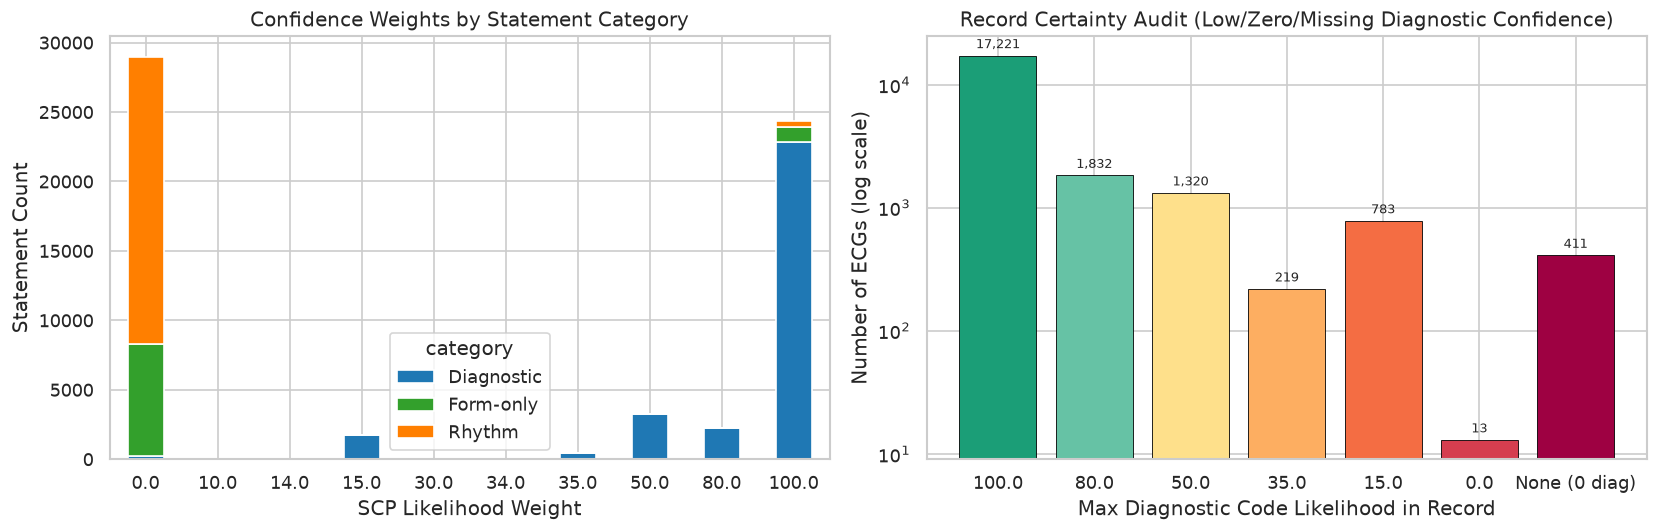

In [2]:
diag_codes = set(scp_df.index[scp_df["diagnostic"] == 1.0])
form_codes = set(scp_df.index[scp_df["form"] == 1.0])
rhythm_codes = set(scp_df.index[scp_df["rhythm"] == 1.0])

print(f"Diagnostic codes : {len(diag_codes)} | Form codes: {len(form_codes)} | Rhythm codes: {len(rhythm_codes)}")
print(f"Overlap (Diagnostic & Form): {sorted(diag_codes & form_codes)}")

# Flatten all (ecg_id, code, weight) triples
rows = []
for ecg_id, d in df["scp_dict"].items():
    for c, w in d.items():
        cat = (
            "Diagnostic" if c in diag_codes
            else ("Rhythm" if c in rhythm_codes else "Form-only")
        )
        rows.append((ecg_id, c, float(w), cat))
triples = pd.DataFrame(rows, columns=["ecg_id", "code", "weight", "category"])

wt_ct = pd.crosstab(triples["weight"], triples["category"])
print("\nOccurrences of (weight × category) across all 21,799 ECGs:")
display(wt_ct)

# Per-record maximum diagnostic confidence
def max_diag_weight(d: dict) -> float:
    vals = [float(w) for c, w in d.items() if c in diag_codes]
    return max(vals) if vals else -1.0  # -1 = no diagnostic code at all

df["max_diag_weight"] = df["scp_dict"].apply(max_diag_weight)
print("Records grouped by highest diagnostic SCP confidence (-1 = NO diagnostic code):")
print(df["max_diag_weight"].value_counts().sort_index())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
wt_ct.plot(kind="bar", stacked=True, ax=axes[0], color=["#1f78b4", "#33a02c", "#ff7f00"])
axes[0].set_xlabel("SCP Likelihood Weight")
axes[0].set_ylabel("Statement Count")
axes[0].set_title("Confidence Weights by Statement Category")
axes[0].tick_params(axis="x", rotation=0)

mw_counts = df["max_diag_weight"].replace({-1.0: "None (0 diag)"}).value_counts()
mw_order = ["100.0", "80.0", "50.0", "35.0", "15.0", "0.0", "None (0 diag)"]
mw_vals = [df["max_diag_weight"].eq(float(x)).sum() if x != "None (0 diag)" else df["max_diag_weight"].eq(-1.0).sum() for x in mw_order]
bar_colors = ["#1b9e77", "#66c2a5", "#fee08b", "#fdae61", "#f46d43", "#d53e4f", "#9e0142"]
axes[1].bar(mw_order, mw_vals, color=bar_colors, edgecolor="black", lw=0.5)
axes[1].set_yscale("log")
axes[1].set_xlabel("Max Diagnostic Code Likelihood in Record")
axes[1].set_ylabel("Number of ECGs (log scale)")
axes[1].set_title("Record Certainty Audit (Low/Zero/Missing Diagnostic Confidence)")
for i, v in enumerate(mw_vals):
    if v > 0:
        axes[1].text(i, v * 1.15, f"{v:,}", ha="center", fontsize=8)

plt.tight_layout()
plt.show()

## 2.2 Label Quality Anomalies: The "No-Diagnostic-Code → `NORM`" Trap & `NORM` + Pathology Collisions

Let's inspect two critical label-cleaning hazards:
1. **Records with ZERO diagnostic SCP codes** (`max_diag_weight == -1`): What rhythm/form codes do they actually carry? In `PTBXLDataset`, both `_pick_subclass` and `_aggregate_class` return `"NORM"` when no diagnostic code is present — silently labeling **pacemaker (`PACE`)**, **atrial fibrillation (`AFIB`)**, and **supraventricular tachycardia (`SVTAC`)** ECGs as `"NORM"`!
2. **Records containing `NORM` alongside another diagnostic superclass** (e.g., `NORM: 50` + `IMI: 15` or `CD`).

Records with ZERO diagnostic SCP codes: 411 (1.89%)
Top rhythm/form codes inside these '0-diagnostic' records (currently mapped to 'NORM'!):
  PACE     (284x) — normal functioning artificial pacemaker
  AFIB     ( 63x) — atrial fibrillation
  AFLT     ( 49x) — atrial flutter
  ABQRS    ( 17x) — abnormal QRS
  PSVT     ( 15x) — paroxysmal supraventricular tachycardia
  PVC      ( 15x) — ventricular premature complex
  SR       ( 14x) — sinus rhythm
  BIGU     ( 11x) — bigeminal pattern (unknown origin, SV or Ventricular)
  STACH    (  8x) — sinus tachycardia
  SVARR    (  6x) — supraventricular arrhythmia
  SVTAC    (  5x) — supraventricular tachycardia
  STD_     (  5x) — non-specific ST depression



Records labeled BOTH 'NORM' and a pathological superclass: 445
                                                scp_codes superclasses  \
ecg_id                                                                   
218              {'NORM': 80.0, '1AVB': 100.0, 'SR': 0.0}   [CD, NORM]   
235          {'NORM': 100.0, 'LAFB': 100.0, 'SBRAD': 0.0}   [CD, NORM]   
236             {'NORM': 80.0, 'IRBBB': 100.0, 'SR': 0.0}   [CD, NORM]   
291     {'NORM': 80.0, 'IRBBB': 100.0, 'HVOLT': 0.0, '...   [CD, NORM]   
362         {'NORM': 100.0, 'IRBBB': 100.0, 'SARRH': 0.0}   [CD, NORM]   
420     {'NORM': 100.0, 'IRBBB': 100.0, 'LOWT': 0.0, '...   [CD, NORM]   
478          {'NORM': 80.0, 'IRBBB': 100.0, 'SARRH': 0.0}   [CD, NORM]   
586             {'NORM': 80.0, 'IRBBB': 100.0, 'SR': 0.0}   [CD, NORM]   

        validated_by_human  
ecg_id                      
218                   True  
235                   True  
236                   True  
291                   True  
362                  

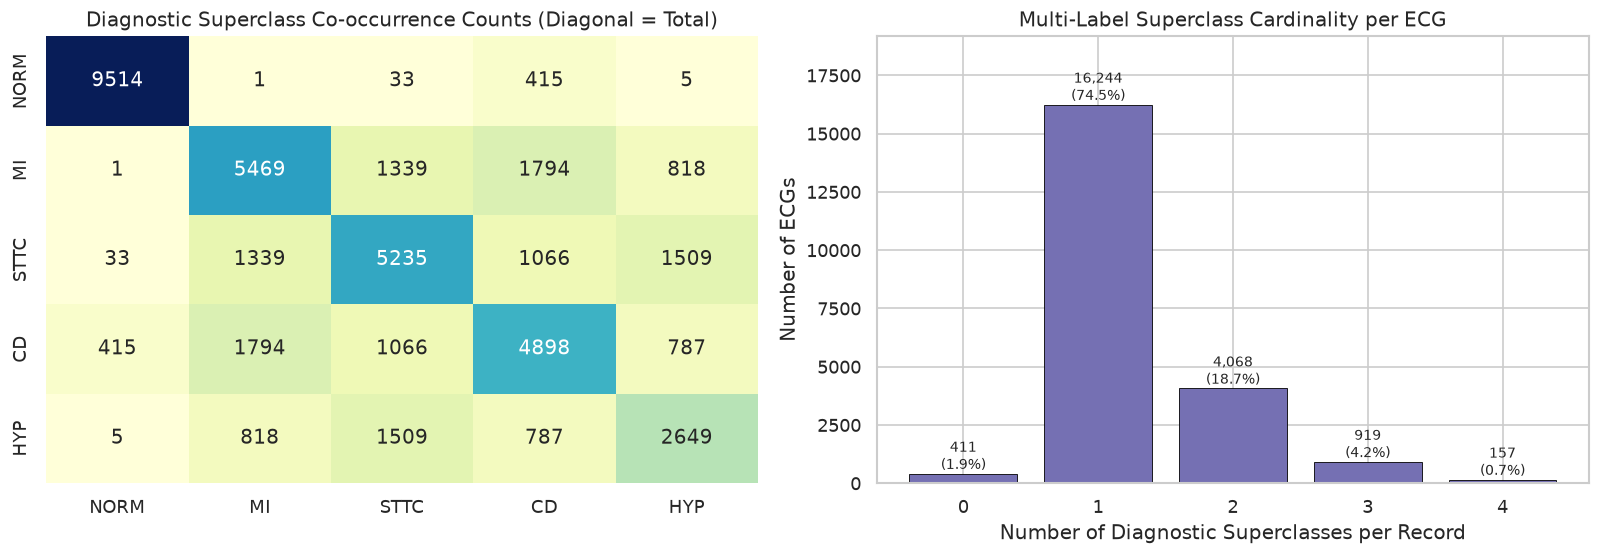

In [3]:
diag_scp = scp_df[scp_df["diagnostic"] == 1.0]

no_diag_df = df[df["max_diag_weight"] == -1.0]
no_diag_codes = pd.Series([c for d in no_diag_df["scp_dict"] for c in d.keys()]).value_counts()
print(f"Records with ZERO diagnostic SCP codes: {len(no_diag_df):,} ({len(no_diag_df)/len(df)*100:.2f}%)")
print("Top rhythm/form codes inside these '0-diagnostic' records (currently mapped to 'NORM'!):")
for code_name, cnt in no_diag_codes.head(12).items():
    desc = scp_df.loc[code_name, "description"]
    print(f"  {code_name:<8} ({cnt:3d}x) — {desc}")

# Multi-superclass membership per record
def get_superclasses(d: dict) -> list[str]:
    return sorted({diag_scp.loc[c, "diagnostic_class"] for c in d if c in diag_scp.index})

df["superclasses"] = df["scp_dict"].apply(get_superclasses)
df["n_superclasses"] = df["superclasses"].apply(len)

norm_plus_other = df[df["superclasses"].apply(lambda s: "NORM" in s and len(s) > 1)]
print(f"\nRecords labeled BOTH 'NORM' and a pathological superclass: {len(norm_plus_other):,}")
if len(norm_plus_other) > 0:
    print(norm_plus_other[["scp_codes", "superclasses", "validated_by_human"]].head(8))

# Co-occurrence matrix across the 5 superclasses
supers = ["NORM", "MI", "STTC", "CD", "HYP"]
cooc = pd.DataFrame(0, index=supers, columns=supers)
for s_list in df["superclasses"]:
    for a in s_list:
        for b in s_list:
            cooc.loc[a, b] += 1

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
sns.heatmap(cooc, annot=True, fmt="d", cmap="YlGnBu", ax=axes[0], cbar=False)
axes[0].set_title("Diagnostic Superclass Co-occurrence Counts (Diagonal = Total)")

n_sup_vc = df["n_superclasses"].value_counts().sort_index()
axes[1].bar(n_sup_vc.index.astype(str), n_sup_vc.values, color="#7570b3", edgecolor="black", lw=0.5)
axes[1].set_xlabel("Number of Diagnostic Superclasses per Record")
axes[1].set_ylabel("Number of ECGs")
axes[1].set_title("Multi-Label Superclass Cardinality per ECG")
for i, v in enumerate(n_sup_vc.values):
    axes[1].text(i, v + 200, f"{v:,}\n({v/len(df)*100:.1f}%)", ha="center", fontsize=8.5)
axes[1].set_ylim(0, n_sup_vc.max() * 1.18)

plt.tight_layout()
plt.show()

## 2.3 Auditing `PTBXLDataset` Single-Label Resolution & Parent–Child Contradictions

Let's examine how `ptbxl/dataset.py` converts multi-label `scp_codes` into a single `(diagnostic_class, diagnostic_subclass)`:
- `_aggregate_class` collects all diagnostic superclasses regardless of weight and returns `sorted(...)[0]` (**alphabetical priority**: `CD` > `HYP` > `MI` > `NORM` > `STTC`!).
- `_pick_subclass` picks the subclass with the **highest weight** (breaking weight ties **reverse-alphabetically**: `max(..., key=lambda item: (item[1], item[0]))`).

**Question**: How often does `PTBXLDataset` output a `diagnostic_subclass` that **does not belong** to its returned `diagnostic_class` (e.g., `diagnostic_class == "CD"` while `diagnostic_subclass == "IMI"` [an `MI` subclass])?

In [4]:
# Build ground-truth subclass -> superclass mapping (accounting for _normalize_subclass)
sub_to_super = {}
for code_name, row in diag_scp.iterrows():
    norm_sub = PTBXLDataset._normalize_subclass(row["diagnostic_subclass"])
    sub_to_super[norm_sub] = row["diagnostic_class"]
sub_to_super["NORM"] = "NORM"

ds_helper = PTBXLDataset.__new__(PTBXLDataset)
resolved = df["scp_dict"].apply(
    lambda d: pd.Series({
        "agg_class": ds_helper._aggregate_class(d, diag_scp),
        "picked_subclass": ds_helper._pick_subclass(d, diag_scp)[0],
    })
)
resolved["expected_parent_class"] = resolved["picked_subclass"].map(sub_to_super)
mismatches = resolved[resolved["agg_class"] != resolved["expected_parent_class"]]

# Also count exact max-weight ties in _pick_subclass
def has_max_weight_tie(d: dict) -> bool:
    by_sub = {}
    for c, w in d.items():
        if c in diag_scp.index:
            s = PTBXLDataset._normalize_subclass(diag_scp.loc[c, "diagnostic_subclass"])
            by_sub[s] = max(by_sub.get(s, 0.0), float(w))
    if len(by_sub) <= 1:
        return False
    mx = max(by_sub.values())
    return sum(1 for v in by_sub.values() if v == mx) > 1

n_ties = int(df["scp_dict"].apply(has_max_weight_tie).sum())
print(f"Records with tied top-weighted diagnostic subclasses : {n_ties:,} ({n_ties/len(df)*100:.1f}%)")
print(f"Records where diagnostic_class != parent(subclass)   : {len(mismatches):,} ({len(mismatches)/len(df)*100:.1f}%)")

print("\nTop 10 (diagnostic_class, diagnostic_subclass) contradictions produced by alphabetical _aggregate_class:")
mismatch_pairs = (
    mismatches.groupby(["agg_class", "picked_subclass", "expected_parent_class"])
    .size()
    .sort_values(ascending=False)
    .head(10)
    .rename("count")
    .reset_index()
)
display(mismatch_pairs)

Records with tied top-weighted diagnostic subclasses : 4,049 (18.6%)
Records where diagnostic_class != parent(subclass)   : 1,932 (8.9%)

Top 10 (diagnostic_class, diagnostic_subclass) contradictions produced by alphabetical _aggregate_class:


,agg_class,picked_subclass,expected_parent_class,count
0,MI,ISC,STTC,323
1,HYP,ISC,STTC,264
2,CD,STTC,STTC,223
3,CD,LVH,HYP,211
4,MI,STTC,STTC,166
5,HYP,STTC,STTC,158
6,CD,NORM,NORM,138
7,CD,LAO/LAE,HYP,88
8,CD,IMI,MI,58
9,CD,ISC,STTC,51


## 2.4 Filtering Waterfall & Split `class_names` Consistency (`min_class_fraction=0.0029`)

`PTBXLDataset.__init__` applies `min_class_fraction=0.0029` **after** filtering to `folds`:
- `PTBXLDataset.train()` → folds `1–8`, `filter_noise=True`
- `PTBXLDataset.val()` → fold `9`, `filter_noise=True`
- `PTBXLDataset.test()` → fold `10`, `filter_noise=False`

Let's check:
1. How many records are dropped at each stage of the pipeline?
2. Does `train.class_names == val.class_names == test.class_names`? (If not, integer class indices `0..C-1` derived from `ds.class_names` will **misalign** between train, val, and test!)

Split sizes -> train: 14,071 | val: 1,773 | test: 2,156
Class count -> train: 15 | val: 16 | test: 16

train vs val  symmetric diff : {'RAO/RAE'}
train vs test symmetric diff : {'RAO/RAE'}
val   vs test symmetric diff : set()


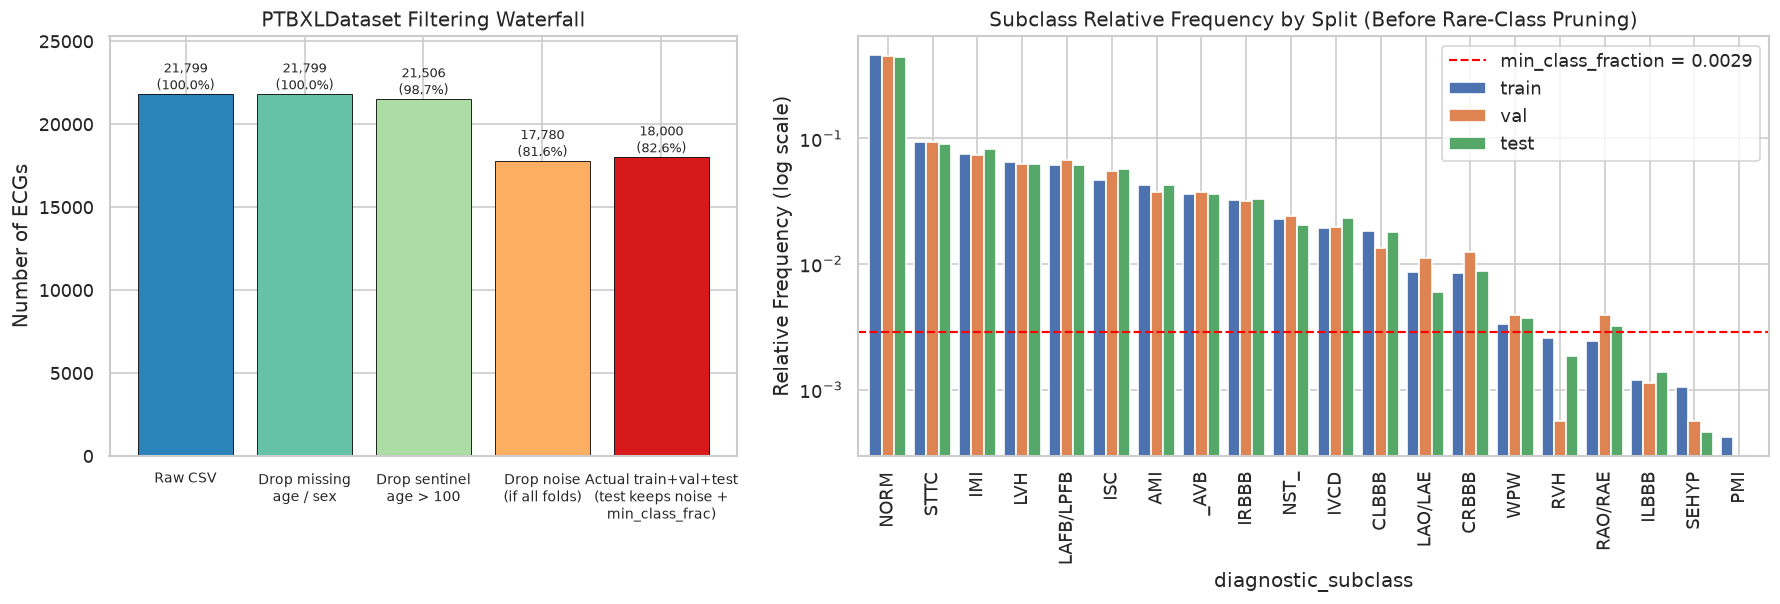

In [5]:
train_ds = PTBXLDataset.train()
val_ds   = PTBXLDataset.val()
test_ds  = PTBXLDataset.test()

print(f"Split sizes -> train: {len(train_ds):,} | val: {len(val_ds):,} | test: {len(test_ds):,}")
print(f"Class count -> train: {len(train_ds.class_names)} | val: {len(val_ds.class_names)} | test: {len(test_ds.class_names)}")
print(f"\ntrain vs val  symmetric diff : {set(train_ds.class_names) ^ set(val_ds.class_names)}")
print(f"train vs test symmetric diff : {set(train_ds.class_names) ^ set(test_ds.class_names)}")
print(f"val   vs test symmetric diff : {set(val_ds.class_names) ^ set(test_ds.class_names)}")

# Step-by-step waterfall across full dataset
s0 = len(df)
df1 = df.dropna(subset=["age", "sex"])
s1 = len(df1)
df2 = df1[df1["age"] <= 100]
s2 = len(df2)
noise_cols = ["static_noise", "burst_noise", "electrodes_problems"]
# Note: fold 10 in PTBXLDataset.test() keeps noisy records, folds 1-9 drop them
is_noisy = df2[noise_cols].notna().any(axis=1)
df3_all_filtered = df2[~is_noisy]
s3_strict = len(df3_all_filtered)
s_retained_splits = len(train_ds) + len(val_ds) + len(test_ds)

stages = [
    "Raw CSV",
    "Drop missing\nage / sex",
    "Drop sentinel\nage > 100",
    "Drop noise\n(if all folds)",
    "Actual train+val+test\n(test keeps noise +\nmin_class_frac)",
]
counts = [s0, s1, s2, s3_strict, s_retained_splits]

# Subclass frequency comparison before min_class_fraction across splits
raw_train = PTBXLDataset.train(min_class_fraction=0.0)
raw_val   = PTBXLDataset.val(min_class_fraction=0.0)
raw_test  = PTBXLDataset.test(min_class_fraction=0.0)

freq_df = pd.DataFrame({
    "train": raw_train._df["diagnostic_subclass"].value_counts(normalize=True),
    "val":   raw_val._df["diagnostic_subclass"].value_counts(normalize=True),
    "test":  raw_test._df["diagnostic_subclass"].value_counts(normalize=True),
}).fillna(0.0).sort_values("train", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.45]})

axes[0].bar(stages, counts, color=["#2b83ba", "#66c2a5", "#abdda4", "#fdae61", "#d7191c"], edgecolor="black", lw=0.5)
axes[0].set_ylabel("Number of ECGs")
axes[0].set_title("PTBXLDataset Filtering Waterfall")
axes[0].tick_params(axis="x", labelsize=8.5)
for i, v in enumerate(counts):
    axes[0].text(i, v + 300, f"{v:,}\n({v/s0*100:.1f}%)", ha="center", fontsize=8)
axes[0].set_ylim(0, s0 * 1.16)

freq_df.plot(kind="bar", ax=axes[1], width=0.82)
axes[1].axhline(0.0029, color="red", ls="--", lw=1.3, label="min_class_fraction = 0.0029")
axes[1].set_yscale("log")
axes[1].set_ylabel("Relative Frequency (log scale)")
axes[1].set_title("Subclass Relative Frequency by Split (Before Rare-Class Pruning)")
axes[1].legend()

plt.tight_layout()
plt.show()

## Key Label-Cleaning Takeaways (Notebook 02)

1. **Zero-Diagnostic Records Mapped to `"NORM"` (`411` ECGs)**: Records containing only rhythm/form codes (including `AFIB`, `PACE`, `STACH`, `SARRH`) have no diagnostic SCP code and get defaulted to `"NORM"` in `PTBXLDataset`. Drop `max_diag_weight < 0` (or require explicit `'NORM' in scp_codes`) before supervised diagnostic training!
2. **Low-Confidence Statements (`weight <= 50` or `0.0`)**: Hundreds of records rely on diagnostic statements with `weight <= 50` ("questionable/possible") or `0.0`. Filtering or sample-weighting by `likelihood >= 50` (or `>= 80`) substantially sharpens label quality.
3. **Parent–Child Contradictions in Single-Label Mode**: Because `_aggregate_class` sorts superclasses alphabetically while `_pick_subclass` selects the max-weight subclass, multi-pathology ECGs frequently get mismatched `(diagnostic_class, diagnostic_subclass)` pairs. Deriving `diagnostic_class = sub_to_super[diagnostic_subclass]` guarantees hierarchy consistency.
4. **Per-Split `min_class_fraction` Risk**: Computing `min_class_fraction` independently inside each split (`train`, `val`, `test`) risks dropping borderline rare subclasses in one split but keeping them in another — always derive the kept vocabulary on `train` (or full dataset) and pass an explicit `allowed_classes` list to `val`/`test`.